# Run Simulation - Provincial Canada

This notebook covers the full workflow end-to-end:
1. **Build the data pickle**: read raw ICIO, WIOD-SEA, HFCS, and supporting input files; calibrate initial conditions for all 10 provinces; and save to `output/`.
2. **Run the simulation**: load the pickle and step the ABM forward with TFP and technical-coefficient growth enabled.
3. **Plot results**: produce per-province GDP and industry production charts.

## What this model does

The model simulates a multi-sector economy in which firms, households, banks, and government entities interact over discrete timesteps. In this demo notebook, `time_unit = 3`, so each timestep is 3 months. Each province is treated as a separate economy with its own firms, households, banks, and government entity, calibrated from a 2014 provincial input-output table. The current provincial table has 43 industry sectors.

**Productivity growth is enabled.** Firms invest a fraction of available cash into two kinds of improvement each timestep:
- **TFP growth** (`SimpleTFPGrowth`): raises total factor productivity so each unit of input produces more output over time.
- **Technical coefficient growth** (`SimpleTechnicalGrowth`): gradually reduces input requirements per unit of output.



## How this differs from the scenario-comparison notebook

This notebook is the basic smoke-test and handoff workflow: it creates one calibrated provincial data pickle, runs one simulation, saves one HDF5 results file, and produces a few standard plots. The companion `Sample_macroabm-CANADA_run_time_iteration.ipynb` is for comparing multiple scenario configurations and averaging repeated trials.

## Directory structure

```text
repo-root/
  raw_data/                         # external raw data folder supplied by the user
    icio/
    wiod_sea/
    hfcs/
    ...
  output/                           # created automatically by this notebook
    data_provincial_model.pkl       # PKL_PATH, written by Section 4 and read by Section 5
    results_provinces_wTFP.h5
    *.png
  macro_data/
  macromodel/
  Sample_macroabm-Canada_provincial_run.ipynb
```

## How to run

Run the cells top to bottom, in order. Section 4 (Create data pickle) takes several minutes and only needs to run once; it is skipped automatically if the pickle already exists. If you change `time_unit`, raw-data inputs, or the IO table, delete/regenerate the pickle before rerunning the simulation.


## 1 — Autoreload

In [1]:
%load_ext autoreload
%autoreload all

## 2 — Paths

- `INPUT_PATH` — point it to raw data directory folder, containing the OECD ICIO tables, WIOD socioeconomic accounts, HFCS survey files, and other required inputs.
- `PKL_PATH` — where the calibrated `DataWrapper` pickle is saved (`output/data_provincial.pkl`). The `output/` directory is created automatically.
- `OUTPUT_FILENAME` — name of the HDF5 results file written at the end of the simulation.

In [2]:
from pathlib import Path

# Point this to the raw-data folder that contains icio/, wiod_sea/, hfcs/, exchange_rates/, etc.
# Example: INPUT_PATH = Path(r"/path/to/raw_data")
INPUT_PATH       = Path(r"C:\Users\LSTERN\macroabm-ca\raw_data")
BASE_DIR         = Path.cwd()
OUTPUT_DIRECTORY = BASE_DIR / "output"
# OUTPUT_FILENAME  = "results_provinces_wTFP.h5"
PKL_PATH         = OUTPUT_DIRECTORY / "data_provincial_model.pkl"

OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

print(f"Input path : {INPUT_PATH}  exists={INPUT_PATH.exists()}")
print(f"Pickle     : {PKL_PATH}")


Input path : C:\Users\LSTERN\macroabm-ca\raw_data  exists=True
Pickle     : c:\Users\LSTERN\macroabm-ca\scenarios\output\data_provincial_model.pkl


## 3 — Imports

In [3]:
import macro_data
from macro_data import DataWrapper, configuration_utils
from macro_data.configuration.countries import Country as CountryCode
from macro_data.configuration.region import Region
from macromodel.configurations import SimulationConfiguration, CountryConfiguration
from macromodel.simulation import Simulation

## 3 - Data configuration

This section builds the `DataConfiguration` object that tells the model how to read and structure the raw input data for the 10 Canadian provinces.

**Key settings:**

| Setting | Value | Meaning |
|---------|-------|---------|
| `use_disagg_can_2014_reader` / `can_disaggregation` | `True` | Use the Canada-specific IO reader with the current provincial table. |
| `aggregation_structure` | `{CAN: [10 provinces]}` | Replace the single Canada entry with 10 separate provincial economies. |
| `single_firm_per_industry` | `True` | Creates one representative firm per sector in each province. |
| `scale` | `1000` | Number of real-world households represented by each synthetic household; see `CountryDataConfiguration.scale` and `hfcs_synthetic_population.py`. |
| `proxy_country_dict` | `{"CAN": "FRA"}` | Use France as the EU proxy for household finance survey data. |

Each province inherits the same base configuration as the national CAN entry: one representative firm per sector, one bank, and one government entity.


In [4]:
data_config = configuration_utils.default_data_configuration(
    countries=["CAN"],
    aggregate_industries=False,
    proxy_country_dict={"CAN": "FRA"},
    use_disagg_can_2014_reader=True,
)

data_config.year                 = 2014
data_config.time_unit            = 3      # demo setting: 3 months per timestep = quarterly
data_config.can_disaggregation   = True
data_config.aggregate_industries = False
data_config.prune_date           = None
data_config.seed                 = 0

base_config = data_config.country_configs[CountryCode("CAN")]
base_config.single_firm_per_industry  = True
base_config.single_bank               = True
base_config.single_government_entity  = True
base_config.firms_configuration.constructor = "Default"
base_config.scale = 1000              # real-world households represented by each synthetic household

provinces = [
    Region.from_code("CAN_AB", "Alberta"),
    Region.from_code("CAN_BC", "British Columbia"),
    Region.from_code("CAN_MB", "Manitoba"),
    Region.from_code("CAN_NB", "New Brunswick"),
    Region.from_code("CAN_NL", "Newfoundland and Labrador"),
    Region.from_code("CAN_NS", "Nova Scotia"),
    Region.from_code("CAN_ON", "Ontario"),
    Region.from_code("CAN_PE", "Prince Edward Island"),
    Region.from_code("CAN_QC", "Quebec"),
    Region.from_code("CAN_SK", "Saskatchewan"),
]

for province in provinces:
    data_config.country_configs[province] = base_config
    data_config.country_configs[province].eu_proxy_country = CountryCode("FRA")

data_config.aggregation_structure = {CountryCode("CAN"): provinces}

print(f"Provinces       : {[str(p) for p in provinces]}")
print(f"Config entries  : {len(data_config.country_configs)}")
print(f"Time unit       : {data_config.time_unit} months/step")


Provinces       : ['CAN_AB', 'CAN_BC', 'CAN_MB', 'CAN_NB', 'CAN_NL', 'CAN_NS', 'CAN_ON', 'CAN_PE', 'CAN_QC', 'CAN_SK']
Config entries  : 11
Time unit       : 3 months/step


## 4 - Create data pickle

**Only needs to run once.** Reads all raw data files, calibrates initial conditions, and saves to `output/data_provincial_model.pkl`.

`DataWrapper.from_config` performs these steps:
1. Reads the provincial IO table and WIOD socioeconomic accounts.
2. Matches investment matrices to value-added data through the `icio_sea_matching` step.
3. Constructs household wealth distributions from HFCS survey microdata.
4. Builds firm-level initial conditions including wages, capital stocks, inventories, and production targets.

`creator.save(PKL_PATH)` serialises the result. Once this file exists, skip this cell on subsequent runs and proceed directly to Section 5.


In [5]:
import time

if PKL_PATH.exists():
    print(f"Pickle already exists at {PKL_PATH} — skipping data creation.")
else:
    t0 = time.time()
    creator = DataWrapper.from_config(
        configuration=data_config,
        raw_data_path=INPUT_PATH,
        single_hfcs_survey=True,
    )
    creator.save(PKL_PATH)
    print(f"Pickle saved to {PKL_PATH}  ({(time.time() - t0) / 60:.1f} min)")

Pickle already exists at c:\Users\LSTERN\macroabm-ca\scenarios\output\data_provincial_model.pkl — skipping data creation.


## 5 — Load data

Loads the `DataWrapper` saved in Section 4. `DataWrapper.init_from_pickle` is the correct loader when the pickle was written with `creator.save()` (which serialises a dict). If you have a pickle written with `pkl.dump(data_wrapper, f)`, use `pkl.load(f)` instead.

In [6]:
data = DataWrapper.init_from_pickle(PKL_PATH)

n_industries = data.n_industries
industries   = data.industries
print(f"n_industries : {n_industries}")
print(f"industries   : {list(industries)}")

n_industries : 43
industries   : ['A', 'B05a', 'B05b', 'B05c', 'B07', 'B09', 'C10T12', 'C13T15', 'C16', 'C17', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24a', 'C24b', 'C25', 'C26', 'C27', 'C28', 'C29', 'C30', 'C31T33', 'D', 'E', 'F', 'G', 'H49', 'H50', 'H51', 'H52', 'H53', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R_S']


## 6 - Simulation parameters

This notebook is a short demo with `time_unit = 3`, so each timestep represents 3 months and four timesteps equal one year.

| Parameter | Value | Meaning |
|-----------|-------|---------|
| `TIMESTEPS` | 16 | Number of 3-month timesteps to simulate (4 years) |
| `SEED` | 0 | Random seed for reproducibility |
| `tfp_base_growth_rate` | 0.001 | Autonomous TFP growth per timestep, independent of investment |
| `tfp_investment_elasticity` | 0.5 | How strongly TFP responds to investment spending |
| `productivity_growth_investment_effectiveness` | 0.3 | Fraction of TFP investment that actually improves productivity |
| `technical_coefficients_investment_effectiveness` | 0.3 | Fraction of technical investment that reduces input coefficients |
| `diminishing_returns_factor` | 0.1 | Rate at which returns to technical investment diminish |
| `hurdle_rate` | 0.01 | Minimum expected return required before a firm invests in productivity |
| `tfp_investment_share` | 0.5 | Share of productivity budget going to TFP rather than technical coefficients |
| `max_investment_fraction` | 0.2 | Maximum share of a firm's cash that can be spent on productivity investment |

For branch validation and comparison runs, also read `docs/canada_provincial_io_development.md`; those runs may use a different timestep convention and seed.


In [7]:
import random
TIMESTEPS = 16
SEED      = 0

# TFP / investment parameters used for this short demo run.
tfp_base_growth_rate              = 0.001
tfp_investment_elasticity         = 0.5
productivity_growth_investment_effectiveness          = 0.3
technical_coefficients_investment_effectiveness       = 0.3
diminishing_returns_factor                            = 0.1
hurdle_rate                                           = 0.01
investment_effectiveness                              = 0.3
technical_investment_effectiveness                    = 0.3
technical_diminishing_returns                         = 0.1
tfp_investment_share                                  = 0.5
max_investment_fraction                               = 0.2

print(f"Timesteps : {TIMESTEPS}")
print(f"Seed      : {SEED}")
print("Note: this notebook uses a short quarterly demo setup. See docs/canada_provincial_io_development.md for branch validation notes.")


Timesteps : 16
Seed      : 0
Note: this notebook uses a short quarterly demo setup. See docs/canada_provincial_io_development.md for branch validation notes.


## 7 - Build simulation configuration

A `SimulationConfiguration` specifies how agents behave — it is separate from the calibrated data (`DataWrapper`). This lets you change the model's rules (e.g. pricing behaviour, growth mechanisms) without reprocessing raw data.

Each province gets a `CountryConfiguration` built with `n_industry_default`, which sets up one representative firm per industry sector. The `for` loop then attaches the productivity investment configuration to each province's firms block.

**Key design choices in this notebook:**
- No energy substitution bundles — firms use the standard Leontief production function.
- Productivity investment is active for all provinces with the parameters from Section 6.

## 8 - Run and save

`Simulation.from_datawrapper` combines the calibrated initial conditions (`DataWrapper`) with the behavioural rules (`SimulationConfiguration`) to create a ready-to-run simulation object.

`model.run()` steps through all `TIMESTEPS` periods. With the demo `time_unit = 3`, each period is 3 months.

`model.save()` writes the full time series to HDF5. The file can be large for long runs; subsequent sections load only what is needed for plotting.

In [8]:
n_scenarios = 3
### gloabl cross-scenario variables     TODO: update so that ts_ variables can vary across scenarios and seeds
ts_time = []

provinces = {
    "CAN_AB": "Alberta",
    "CAN_BC": "British Columbia",
    "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick",
    "CAN_NL": "Newfoundland and Labrador",
    "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",
    "CAN_PE": "Prince Edward Island",
    "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}
keys = provinces.keys()
ts_tax_policy = [{k: [] for k in keys} for _ in range(n_scenarios)]

ts_households_n_adults = {}
ts_households_type = {}
ts_households_corr_individuals = {}
ts_individuals_activity_status = {}
ts_individuals_education = {}
ts_individuals_corr_hh = {}

In [9]:
def run_scenario(
    i_scenario: int,
    use_taxation_policies: bool,
    policy_type: int,
    rate: list[tuple[float, float]]
    ) -> None:

    """Calculate estimate of income to be withheld to pay personal income tax for one timestep
            
    Attributes:
            i_scenario (int): Scenario index
            use_taxation_policies (bool): Toggle for taxation policies
            policy_type (int): Flag for policy type: 0 = Flat, 1 = Progressive, 2=TBD
            brackets (list[tuple[float, float]]): Taxation rate as recorded as (threshold, rate)        

    Returns:
            None
    """

    # set cross scenario variables as global
    global ts_tax_policy
    global ts_time
    global ts_households_n_adults
    global ts_households_type
    global ts_households_corr_individuals
    global ts_individuals_activity_status
    global ts_individuals_education
    global ts_individuals_corr_hh

    SCENARIO = "scenario_" + str(i_scenario)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    print(f"Output     : {OUTPUT_DIRECTORY / OUTPUT_FILENAME}")

    provinces = [
        Region.from_code("CAN_AB", "Alberta"),
        Region.from_code("CAN_BC", "British Columbia"),
        Region.from_code("CAN_MB", "Manitoba"),
        Region.from_code("CAN_NB", "New Brunswick"),
        Region.from_code("CAN_NL", "Newfoundland and Labrador"),
        Region.from_code("CAN_NS", "Nova Scotia"),
        Region.from_code("CAN_ON", "Ontario"),
        Region.from_code("CAN_PE", "Prince Edward Island"),
        Region.from_code("CAN_QC", "Quebec"),
        Region.from_code("CAN_SK", "Saskatchewan"),
    ]

    config = SimulationConfiguration(
        seed=SEED,
        country_configurations={
            province: CountryConfiguration.n_industry_default(n_industries=n_industries)
            for province in provinces
        },
        t_max=TIMESTEPS,
    )

    for province in provinces:  
        firms = config.country_configurations[province].firms

        firms.functions.productivity_investment_planner.name = "SimpleProductivityInvestmentPlanner"
        firms.functions.productivity_investment_planner.parameters.update({
            "n_firms":                      n_industries,
            "tfp_investment_share":          tfp_investment_share,
            "max_investment_fraction":       max_investment_fraction,
            "investment_effectiveness":      investment_effectiveness,
            "technical_investment_effectiveness": technical_investment_effectiveness,
            "technical_diminishing_returns": technical_diminishing_returns,
            "hurdle_rate":                   hurdle_rate,
        })

        firms.functions.productivity_growth.name = "SimpleTFPGrowth"
        firms.functions.productivity_growth.parameters = {
            "investment_effectiveness": productivity_growth_investment_effectiveness,
        }
        firms.parameters.tfp_base_growth_rate     = tfp_base_growth_rate
        firms.parameters.tfp_investment_elasticity = tfp_investment_elasticity

        firms.functions.technical_coefficients_growth.name = "SimpleTechnicalGrowth"
        firms.functions.technical_coefficients_growth.parameters = {
            "investment_effectiveness":  technical_coefficients_investment_effectiveness,
            "diminishing_returns_factor": diminishing_returns_factor,
        }

        # Taxation configuration (NOTE: can be set differently for each province)
        config.country_configurations[province].use_taxation_policies = use_taxation_policies
        config.country_configurations[province].policy_type = policy_type
        config.country_configurations[province].rate = rate
        config.country_configurations[province].time_unit = data_config.time_unit

    print("Configuration built.")

    import time

    model = Simulation.from_datawrapper(datawrapper=data, simulation_configuration=config)

    t0 = time.time()

    # initialize non-timeseries variables for use during analysis
    ts_time = []
    
    keys = model.countries.keys()
    ts_households_n_adults = {k: [] for k in keys}
    ts_households_type = {k: [] for k in keys}
    ts_households_corr_individuals = {k: [] for k in keys}
    ts_individuals_activity_status = {k: [] for k in keys}
    ts_individuals_education = {k: [] for k in keys}
    ts_individuals_corr_hh = {k: [] for k in keys}

    # store timeseries non-h5 variables (initialization values)
    ts_time.append(str(model.timestep))
    for name, country in model.countries.items():
        ts_tax_policy[i_scenario-1][name].append(model.countries[name].personal_income_tax.get_rate())
        ts_households_type[name].append(model.countries[name].households.states["Type"])
        ts_households_n_adults[name].append(model.countries[name].households.states["Number of Adults"])
        ts_households_corr_individuals[name].append(model.countries[name].households.states["corr_individuals"])
        
        ts_individuals_activity_status[name].append(model.countries[name].individuals.states["Activity Status"])
        ts_individuals_education[name].append(model.countries[name].individuals.states["Education"])
        ts_individuals_corr_hh[name].append(model.countries[name].individuals.states["Corresponding Household ID"]) 

    for t in range(TIMESTEPS):
        model.iterate(t)

        # store timeseries non-h5 variables (iteration values)
        ts_time.append(str(model.timestep))
        for name, country in model.countries.items():
            ts_tax_policy[i_scenario-1][name].append(model.countries[name].personal_income_tax.get_rate())
            ts_households_type[name].append(model.countries[name].households.states["Type"])
            ts_households_n_adults[name].append(model.countries[name].households.states["Number of Adults"])
            ts_households_corr_individuals[name].append(model.countries[name].households.states["corr_individuals"])

            ts_individuals_activity_status[name].append(model.countries[name].individuals.states["Activity Status"])
            ts_individuals_education[name].append(model.countries[name].individuals.states["Education"])
            ts_individuals_corr_hh[name].append(model.countries[name].individuals.states["Corresponding Household ID"]) 

    print(f"Simulation complete in {(time.time() - t0) / 60:.1f} min")

    ## save()
    model.save(save_dir=OUTPUT_DIRECTORY, file_name=OUTPUT_FILENAME)

    ### save_selective()
    # countries = ['CAN_BC']
    # agents = ['economy', 'central_government', 'individuals', 'households']
    # model.save_selective(countries, agents, save_dir=OUTPUT_DIRECTORY, file_name=OUTPUT_FILENAME)
    
    print(f"Results saved to {OUTPUT_DIRECTORY / OUTPUT_FILENAME}")

In [10]:
scenario_labels=[]

In [11]:
i_scenario = 1  # scenario index
scenario_labels.append("Existing brackets")
# https://www.canada.ca/en/revenue-agency/services/tax/individuals/tax-rates-brackets/current-year.html

# Taxation policy parameters
use_taxation_policies = True
policy_type = 1
rate = [
    (13216, 0.0),       # basic rate refund is approx by a bracket with zero rate
    (50363, 0.056),
    (100728, 0.077),
    (115648, 0.105),
    (140430, 0.1229),
    (190405, 0.147),
    (265545, 0.168),
    (float('inf'), 0.205)
]

run_scenario(i_scenario, use_taxation_policies, policy_type, rate)

Output     : c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_1.h5
Configuration built.
t: 0, timestep: 2014-1
t: 1, timestep: 2014-4


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 2, timestep: 2014-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 3, timestep: 2014-10


...

t: 14, timestep: 2017-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 15, timestep: 2017-10


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

Simulation complete in 0.4 min
Results saved to c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_1.h5


In [12]:
i_scenario = 2  # scenario index
scenario_labels.append("Expanded basic rate")
# https://conservativebc.ca/conservatives-will-cut-your-taxes-by-1000/

# Taxation policy parameters
use_taxation_policies = True
policy_type = 1
rate = [
    (32000, 0.0),       # increased from 13216 - basic rate refund is approx by a bracket with zero rate
    (50363, 0.056),
    (100728, 0.077),
    (115648, 0.105),
    (140430, 0.1229),
    (190405, 0.147),
    (265545, 0.168),
    (float('inf'), 0.205)
]

run_scenario(i_scenario, use_taxation_policies, policy_type, rate)

Output     : c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_2.h5
Configuration built.
t: 0, timestep: 2014-1
t: 1, timestep: 2014-4


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 2, timestep: 2014-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 3, timestep: 2014-10


...

t: 14, timestep: 2017-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 15, timestep: 2017-10


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

Simulation complete in 0.5 min
Results saved to c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_2.h5


In [13]:
i_scenario = 3  # scenario index
scenario_labels.append("Increased upper brackets")
# see https://www.bcndp.ca/releases/build-bc-strong-eby-will-ask-wealthy-pitch-bit-more

# Taxation policy parameters
use_taxation_policies = True
policy_type = 1
rate = [
    (13216, 0.0),       # basic rate refund is approx by a bracket with zero rate
    (50363, 0.056),
    (100728, 0.077),
    (115648, 0.105),
    (140430, 0.1229),
    (190405, 0.167),    # increase by 2% from 0.147
    (265545, 0.188),    # increase by 2% from 0.168
    (1000000, 0.225),   # new bracket
    (float('inf'), 0.245)
]

run_scenario(i_scenario, use_taxation_policies, policy_type, rate)

Output     : c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_3.h5
Configuration built.
t: 0, timestep: 2014-1
t: 1, timestep: 2014-4


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 2, timestep: 2014-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 3, timestep: 2014-10


...

t: 14, timestep: 2017-7


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

t: 15, timestep: 2017-10


C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:318: RuntimeWarning: invalid value encountered in multiply
  quantities = production[:, np.newaxis] * effective_coefficients
C:\Users\LSTERN\macroabm-ca\macromodel\agents\firms\func\technical_coefficients_growth.py:255: RuntimeWarning: invalid value encountered in 

Simulation complete in 0.5 min
Results saved to c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_3.h5


In [14]:
# i_scenario = 4  # scenario index

# # Taxation policy parameters
# use_taxation_policies = True
# policy_type = 0
# rate = [
#     (float('inf'), 0.09)
# ]

# run_scenario(i_scenario, use_taxation_policies, policy_type, rate)

In [15]:
### scenario summary
province = 'CAN_BC'
for i in range(n_scenarios):
    print(f"{province} {scenario_labels[i]}:")
    for t in range(len(ts_time)):
        print(f"t: {ts_time[t]} \t{ts_tax_policy[i]['CAN_BC'][t]}")

CAN_BC Existing brackets:
t: 2014-1 	[(37606.0, 0.0506), (75213.0, 0.077), (86354.0, 0.105), (104858.0, 0.1229), (150000.0, 0.147), (inf, 0.168)]
t: 2014-4 	[(37606.0, 0.0506), (75213.0, 0.077), (86354.0, 0.105), (104858.0, 0.1229), (150000.0, 0.147), (inf, 0.168)]
t: 2014-7 	[(37606.0, 0.0506), (75213.0, 0.077), (86354.0, 0.105), (104858.0, 0.1229), (150000.0, 0.147), (inf, 0.168)]
t: 2014-10 	[(37606.0, 0.0506), (75213.0, 0.077), (86354.0, 0.105), (104858.0, 0.1229), (150000.0, 0.147), (inf, 0.168)]
t: 2015-1 	[(37869.0, 0.0506), (75740.0, 0.077), (86958.0, 0.105), (105592.0, 0.1229), (151050.0, 0.147), (inf, 0.168)]
t: 2015-4 	[(37869.0, 0.0506), (75740.0, 0.077), (86958.0, 0.105), (105592.0, 0.1229), (151050.0, 0.147), (inf, 0.168)]
t: 2015-7 	[(37869.0, 0.0506), (75740.0, 0.077), (86958.0, 0.105), (105592.0, 0.1229), (151050.0, 0.147), (inf, 0.168)]
t: 2015-10 	[(37869.0, 0.0506), (75740.0, 0.077), (86958.0, 0.105), (105592.0, 0.1229), (151050.0, 0.147), (inf, 0.168)]
t: 2016-1 	[

In [16]:
ts_tax_policy[0][province][0]

[(37606.0, 0.0506),
 (75213.0, 0.077),
 (86354.0, 0.105),
 (104858.0, 0.1229),
 (150000.0, 0.147),
 (inf, 0.168)]

In [17]:
ts_tax_policy[0][province][16]

[(39676.0, 0.0506),
 (79353.0, 0.077),
 (91107.0, 0.105),
 (110630.0, 0.1229),
 (150000.0, 0.147),
 (inf, 0.168)]

In [18]:
SCENARIO = "scenario_" + str(1)
OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
print(f"Output     : {OUTPUT_DIRECTORY / OUTPUT_FILENAME}")

Output     : c:\Users\LSTERN\macroabm-ca\scenarios\output\results_scenario_1.h5


## 9 - Results utilities

Helper functions for loading and inspecting the HDF5 output file. The HDF5 file is organised as a hierarchy: `<province>/<agent_type>/<variable>` (for example, `CAN_ON/firms/production`). The utilities below let you:

- `get_tree`: build a dictionary representation of the file structure.
- `list_dataset_paths`: list every dataset path in the file.
- `load_dataset`: load a specific dataset as a NumPy array.
- `compute_real_gdp`: compute real GDP by deflating nominal GDP with the CPI.
- `get_column_labels`: map industry indices to human-readable names if `can_industries_wnames.csv` is available in the raw-data folder.
- `sum_regions`: aggregate a variable across all provinces.

Running this cell also prints the top-level structure of the results file so you can see what is available.


In [19]:
from typing import Any, Dict, Iterable, List, Optional

import h5py
import numpy as np
import pandas as pd

INDUSTRY_NAMES_CSV = INPUT_PATH / "can_industries_wnames.csv"

TreeNode = Dict[str, Any]


def load_industry_mapping() -> Dict[int, str]:
    if not INDUSTRY_NAMES_CSV.exists():
        return {}
    df = pd.read_csv(INDUSTRY_NAMES_CSV)
    return dict(zip(df["Firm_ID"], df["Industry_Name"]))

def load_industry_codes() -> Dict[int, str]:
    if not INDUSTRY_NAMES_CSV.exists():
        return {}
    df = pd.read_csv(INDUSTRY_NAMES_CSV)
    return dict(zip(df["Firm_ID"], df["Industry"]))


def _build_tree(group: h5py.Group) -> TreeNode:
    tree: TreeNode = {}
    for key in group.keys():
        obj = group[key]
        if isinstance(obj, h5py.Dataset):
            tree[key] = {"type": "dataset"}
        else:
            tree[key] = {"type": "group", "children": _build_tree(obj)}
    return tree


def get_tree(file_path) -> TreeNode:
    with h5py.File(file_path, "r") as f:
        return _build_tree(f)


def list_dataset_paths(tree: TreeNode, prefix: str = "") -> List[str]:
    paths: List[str] = []
    for key in sorted(tree.keys()):
        entry = tree[key]
        current_path = f"{prefix}/{key}" if prefix else key
        if entry["type"] == "dataset":
            paths.append(current_path)
        else:
            paths.extend(list_dataset_paths(entry["children"], current_path))
    return paths


def load_dataset(file_path, dataset_path: str) -> np.ndarray:
    with h5py.File(file_path, "r") as f:
        return f[dataset_path][()]


def compute_real_gdp(file_path, province: str) -> Optional[np.ndarray]:
    gdp_path = f"{province}/economy/gdp_output"
    cpi_path = f"{province}/economy/cpi"
    with h5py.File(file_path, "r") as f:
        if gdp_path not in f or cpi_path not in f:
            return None
        gdp = f[gdp_path][()].astype(float)
        cpi = f[cpi_path][()].astype(float)
    return np.divide(gdp, cpi, out=np.full_like(gdp, np.nan), where=cpi != 0)


def get_column_labels(file_path, dataset_path: str, industry_mapping: Optional[Dict[int, str]] = None) -> Optional[List[str]]:
    columns_path = f"{dataset_path}_columns"
    with h5py.File(file_path, "r") as f:
        if columns_path not in f:
            return None
        cols = np.asarray(f[columns_path][()])
    if cols.ndim == 1:
        if industry_mapping:
            return [industry_mapping.get(int(i), str(int(i))) for i in cols]
        return [str(int(i)) for i in cols]
    if cols.ndim == 2 and cols.shape[1] == 2:
        if industry_mapping:
            return [f"[{industry_mapping.get(int(a), str(int(a)))}, {industry_mapping.get(int(b), str(int(b)))}]" for a, b in cols]
        return [f"[{int(a)}, {int(b)}]" for a, b in cols]
    return [str(x) for x in cols.flatten()]


def merge_trees(trees: Iterable[TreeNode]) -> TreeNode:
    merged: TreeNode = {}
    for tree in trees:
        for key, entry in tree.items():
            if key not in merged:
                merged[key] = entry
                continue
            if merged[key]["type"] == "group" or entry["type"] == "group":
                merged[key] = {
                    "type": "group",
                    "children": merge_trees([
                        merged[key].get("children", {}),
                        entry.get("children", {}),
                    ]),
                }
    return merged


def add_can_region(tree: TreeNode) -> List[str]:
    province_keys = [k for k, v in tree.items() if v["type"] == "group" and k.startswith("CAN_")]
    if province_keys:
        can_children = merge_trees([tree[p]["children"] for p in province_keys])
        tree["CAN"] = {"type": "group", "children": can_children}
    return province_keys


def sum_regions(file_path, province_keys: List[str], tail_path: str) -> Optional[np.ndarray]:
    total: Optional[np.ndarray] = None
    with h5py.File(file_path, "r") as f:
        for province in province_keys:
            full = f"{province}/{tail_path}"
            if full not in f:
                continue
            data = f[full][()].astype(float)
            total = data.copy() if total is None else total + data
    return total


industry_mapping = load_industry_mapping()
industry_codes = load_industry_codes()
print(f"Industry mapping loaded: {len(industry_mapping)} industries")

tree = get_tree(OUTPUT_DIRECTORY / OUTPUT_FILENAME)
regions = add_can_region(tree)
all_paths = list_dataset_paths(tree)

print(f"\nProvinces found : {regions}")
print(f"Total datasets  : {len(all_paths)}")
print("\nTop-level keys:")
for k, v in sorted(tree.items()):
    print(f"  {k}  [{v['type']}]")



Industry mapping loaded: 50 industries

Provinces found : ['CAN_AB', 'CAN_BC', 'CAN_MB', 'CAN_NB', 'CAN_NL', 'CAN_NS', 'CAN_ON', 'CAN_PE', 'CAN_QC', 'CAN_SK']
Total datasets  : 8681

Top-level keys:
  CAN  [group]
  CAN_AB  [group]
  CAN_BC  [group]
  CAN_MB  [group]
  CAN_NB  [group]
  CAN_NL  [group]
  CAN_NS  [group]
  CAN_ON  [group]
  CAN_PE  [group]
  CAN_QC  [group]
  CAN_SK  [group]
  GM  [group]
  ROW  [group]


In [20]:
# print("All dataset paths in H5 file:")
# for p in all_paths:
#     print(f"  {p}")

## 10 - Plot results

Three standard plots are produced and saved to `output/`:
1. Nominal GDP by province.
2. Real GDP by province, computed as GDP divided by CPI where both series are available.
3. Production by industry, summed across provinces, showing the top 10 industries by average output.

PNG files are written to `output/` alongside the HDF5 file.

The first two plots are intended as quick sanity checks: look for explosive paths, sudden breaks, or province trajectories that move implausibly relative to the others. The production plot is a compact way to see whether the largest sectors dominate the run as expected.


Existing brackets - CAN_BC/economy/gdp_output[-1]: 77,244,726,045.84 diff from existing 0.00%
Expanded basic rate - CAN_BC/economy/gdp_output[-1]: 77,244,726,045.84 diff from existing 0.00%
Increased upper brackets - CAN_BC/economy/gdp_output[-1]: 77,244,726,045.84 diff from existing 0.00%


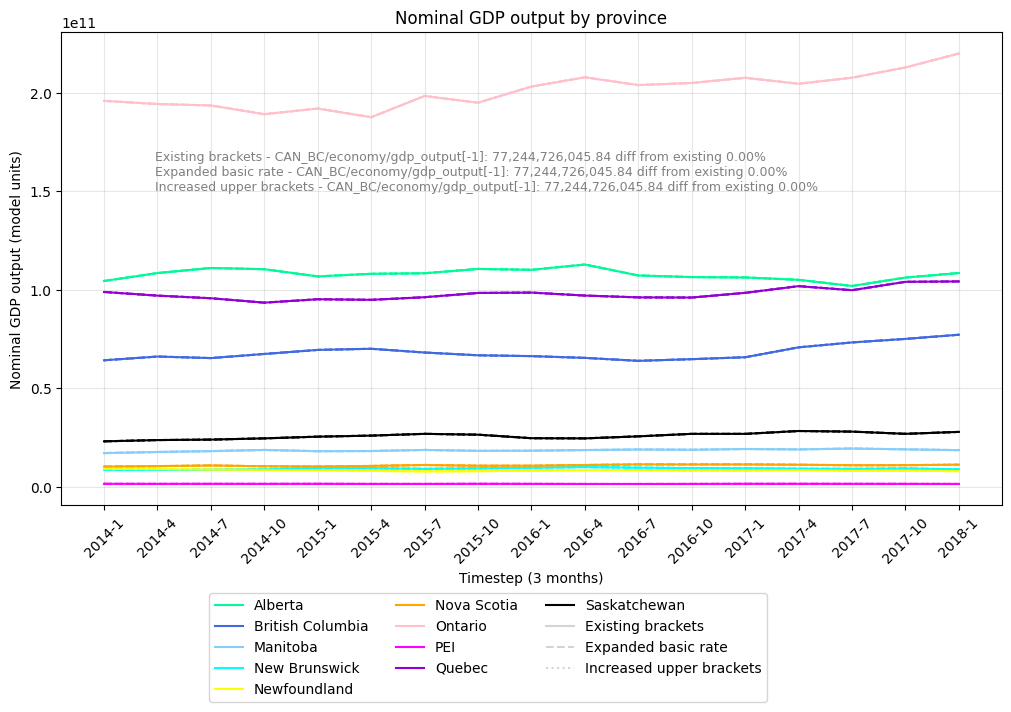

In [33]:
### plot nominal GDP - compare scenarios

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import datetime

PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

PROVINCE_COLOURS = [
    "mediumspringgreen",
    "royalblue",
    "lightskyblue",
    "cyan",
    "yellow",
    "orange",
    "pink",
    "magenta",
    "darkviolet",
    "k",
]

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

data_final = []

# iterate over scenarios
for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        i_colour = 0
        for region in regions:
            variable = "/economy/gdp_output"
            path = f"{region}{variable}"
            if path in f:
                data = f[path][()].astype(float)
                ax.plot(
                    ts_time, 
                    data, 
                    label=PROVINCE_LABELS.get(region, region), 
                    color=PROVINCE_COLOURS[i_colour], 
                    linestyle=linestyles[n]
                )
                i_colour += 1

                if region == 'CAN_BC':
                    temp = data[-1]
                    data_final.append(temp[0])

info = ''
for n in range(n_scenarios):
    a = data_final[0]
    b = data_final[n]
    percent_difference = ((b - a) / ((a + b) / 2) * 100)

    
    text = f"{scenario_labels[n]} - CAN_BC{variable}[-1]: {data_final[n]:,.2f} diff from existing {percent_difference:,.2f}%"
    print(text)
    info += text + "\n"

ax.text(
        0.1, 0.75,              # Position in Axes coordinates
        info,                   # Text string
        transform=ax.transAxes, # Use Axes coordinate system
        ha='left',              # Horizontal alignment
        va='top',               # Vertical alignment
        fontsize=9,             # Font size
        color='grey',           # Text color
        # bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # Optional background
    )

# custom legend
PROVINCE_LABELS_LIST = list(PROVINCE_LABELS.values())
# linestyles = ['solid', 'dashed', 'dotted', 'dashdot']
# markers = ['o','^','s','D','x','*']       # use if not enough linestyles

legend_labels = []
legend_lines = []

# legend labels
for i in range(len(PROVINCE_LABELS_LIST)):
    legend_labels.append(PROVINCE_LABELS_LIST[i])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

# legend lines
for i in range(len(PROVINCE_LABELS_LIST)):
    legend_lines.append(Line2D([0], [0], color = PROVINCE_COLOURS[i], linestyle="-"))
for j in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

plt.legend(
    legend_lines, legend_labels, bbox_to_anchor = (0.15,-0.3), loc="center left", ncol=int(len(legend_labels)/4)
    # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
    # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title("Nominal GDP output by province")
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# ax.set_xticks(ts_time[::4])   # control xtick frequency
ax.set_ylabel("Nominal GDP output (model units)")
# ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_A_nominal_gdp_by_province_" + "ALL" + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()



Existing brackets - CAN_BC/central_government/taxes_income[-1]: 4,288,235,505.76 diff from existing 0.00%
Expanded basic rate - CAN_BC/central_government/taxes_income[-1]: 4,288,235,505.76 diff from existing 0.00%
Increased upper brackets - CAN_BC/central_government/taxes_income[-1]: 4,288,235,505.76 diff from existing 0.00%


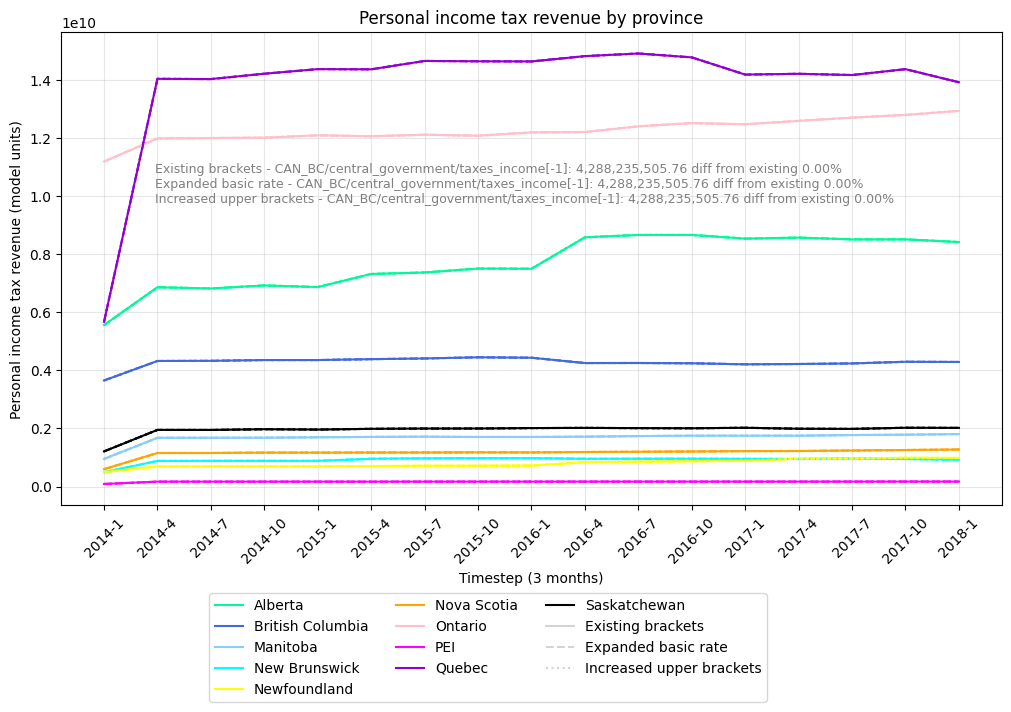

In [22]:
### plot taxes_income - compare scenarios

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import datetime


### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

PROVINCE_COLOURS = [
    "mediumspringgreen",
    "royalblue",
    "lightskyblue",
    "cyan",
    "yellow",
    "orange",
    "pink",
    "magenta",
    "darkviolet",
    "k",
]

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

data_final = []

# iterate over scenarios
for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        i_colour = 0
        for region in regions:
            variable = "/central_government/taxes_income"
            path = f"{region}{variable}"
            if path in f:
                data = f[path][()].astype(float)
                ax.plot(
                    ts_time, 
                    data, 
                    label=PROVINCE_LABELS.get(region, region), 
                    color=PROVINCE_COLOURS[i_colour], 
                    linestyle=linestyles[n],
                )
                i_colour += 1

                if region == 'CAN_BC':
                    temp = data[-1]
                    data_final.append(temp[0])
                
info = ''
for n in range(n_scenarios):
    a = data_final[0]
    b = data_final[n]
    percent_difference = ((b - a) / ((a + b) / 2) * 100)

    
    text = f"{scenario_labels[n]} - CAN_BC{variable}[-1]: {data_final[n]:,.2f} diff from existing {percent_difference:,.2f}%"
    print(text)
    info += text + "\n"

ax.text(
        0.1, 0.725,             # Position in Axes coordinates
        info,                   # Text string
        transform=ax.transAxes, # Use Axes coordinate system
        ha='left',              # Horizontal alignment
        va='top',               # Vertical alignment
        fontsize=9,             # Font size
        color='grey',              # Text color
        # bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # Optional background
    )

legend_labels = []
legend_lines = []

# legend labels
for i in range(len(PROVINCE_LABELS_LIST)):
    legend_labels.append(PROVINCE_LABELS_LIST[i])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

# legend lines
for i in range(len(PROVINCE_LABELS_LIST)):
    legend_lines.append(Line2D([0], [0], color = PROVINCE_COLOURS[i], linestyle="-"))
for j in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

plt.legend(
    legend_lines, legend_labels, bbox_to_anchor = (0.15,-0.3), loc="center left", ncol=int(len(legend_labels)/4)
    # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
    # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title("Personal income tax revenue by province")
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# ax.set_xticks(ts_time[::4])   # control xtick frequency
ax.set_ylabel("Personal income tax revenue (model units)")
# ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_B_taxes_income_by_province_" + "ALL" + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()

In [23]:
# print("top producers in the first timestep")        # NOTE: Clear indication that we need to update IO table
# for i in top_idx:
#     print(f"{industries[i]} \t[{i}]: \t{production_total[0][i]:,.2e}")

In [24]:
def clip_dict_strings(data: dict, max_length: int) -> dict:
    """
    Truncate all string values in a dictionary to max_length characters.
    
    Args:
        data (dict): Dictionary containing values to clip.
        max_length (int): Maximum allowed string length.
    
    Returns:
        dict: New dictionary with clipped string values.
    """
    if not isinstance(data, dict):
        raise TypeError("Input must be a dictionary.")
    if not isinstance(max_length, int) or max_length < 0:
        raise ValueError("max_length must be a non-negative integer.")

    clipped = {}
    for key, value in data.items():
        if isinstance(value, str):
            clipped[key] = value[:max_length]  # Slice string safely
        else:
            clipped[key] = value  # Leave non-string values unchanged
    return clipped

In [25]:
max_len = 15
industry_mapping_clipped = clip_dict_strings(industry_mapping, max_len)

scen 1: [26 27 36 39 35 41 37 40  6 34]
scen 2: [26 27 36 39 35 41 37 40  6 34]
scen 3: [26 27 36 39 35 41 37 40  6 34]


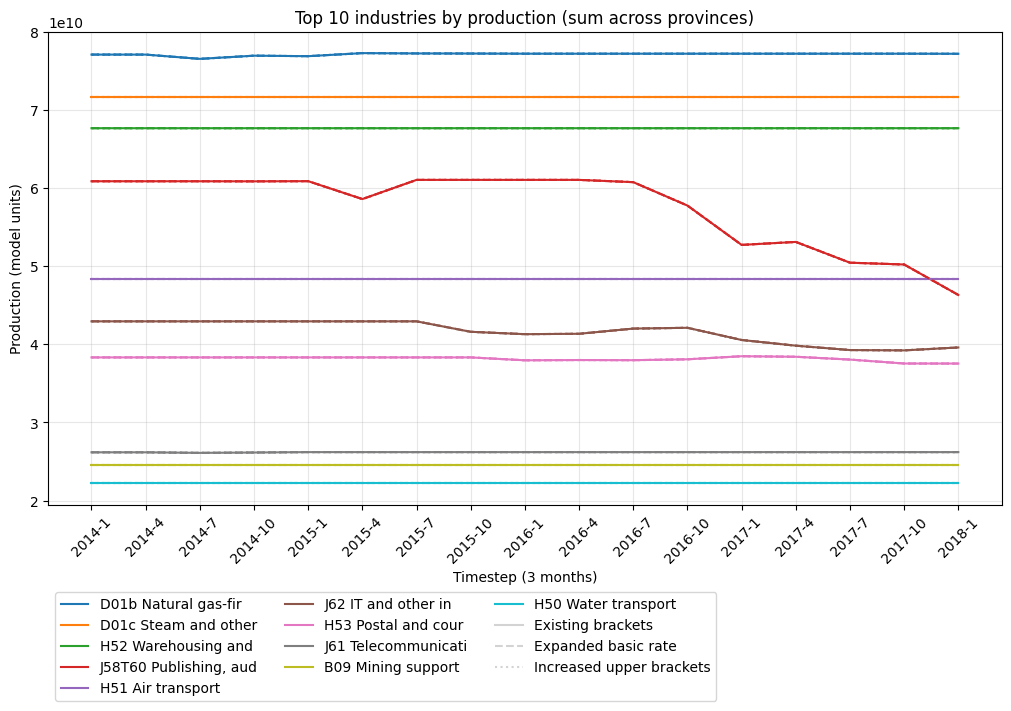

In [27]:
# Plot Production by industry, summed across provinces - compare scenarios

import matplotlib.pyplot as plt
import datetime

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

# iterate over scenarios
for n in range(n_scenarios):

    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    production_total = sum_regions(H5_FILE, regions, "firms/production")

    if production_total is not None:
        labels = get_column_labels(H5_FILE, f"{regions[0]}/firms/production", industry_mapping)
        n_show = min(10, production_total.shape[1])
        mean_prod = production_total.mean(axis=0)
        top_idx = np.argsort(mean_prod)[::-1][:n_show]
        print(f"scen {n+1}: {top_idx}")
        
        i_colour = 0
        for i in top_idx:
            # name = labels[i] if labels else str(i)
            name = industries[i]
            ax.plot(
                ts_time, production_total[:, i],
                color=COLOURS[i_colour],
                label=name,
                linestyle=linestyles[n]
            )
            i_colour += 1

# custom legend
legend_labels = []
for i in range(n_show):
    legend_labels.append(industry_codes[top_idx[i]] + " " + industry_mapping_clipped[top_idx[i]])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for i in range(n_show):
    legend_lines.append(Line2D([0], [0], color = COLOURS[i], linestyle="-"))
for n in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[n]))

plt.legend(
legend_lines, legend_labels, bbox_to_anchor = (0,-0.3), loc="center left", ncol=int(len(legend_labels)/4)
# legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
# legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title(f"Top {n_show} industries by production (sum across provinces)")
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# ax.set_xticks(ts_time[::4])   # control xtick frequency
ax.set_ylabel("Production (model units)")
# ax.legend(fontsize=6, ncol=2)
ax.grid(True, alpha=0.3)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_C_production_top_industries_" + "ALL" + ".png"
plt.savefig(OUTPUT_DIRECTORY / FILENAME, dpi=120)
plt.show()



income
consumption
debt


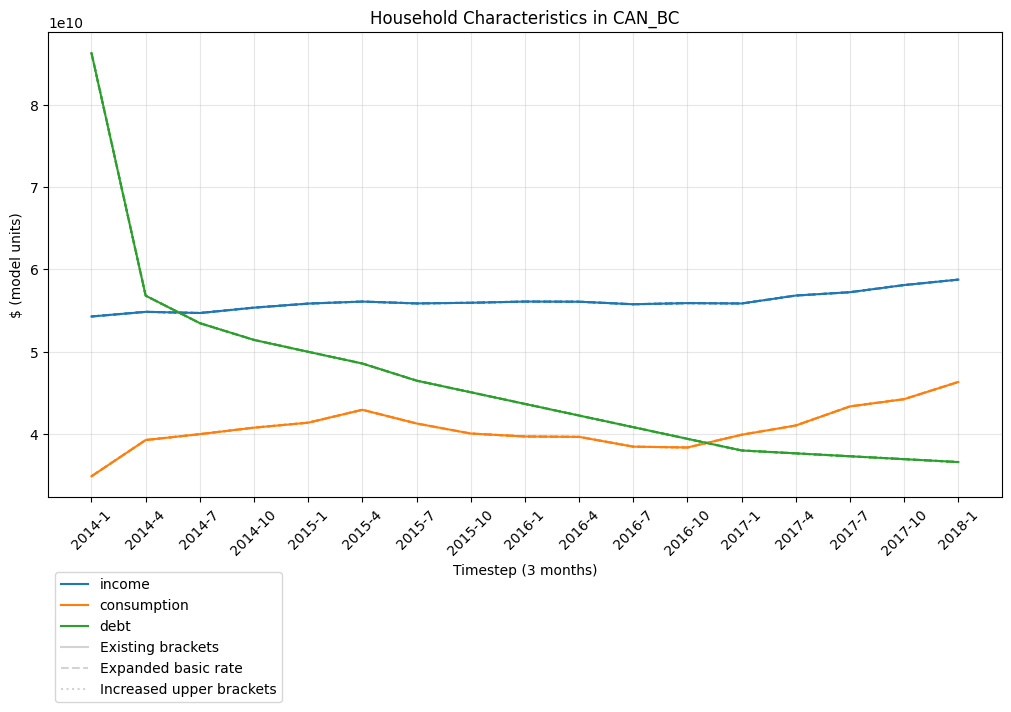

In [28]:
### plot household characteristics

import matplotlib.pyplot as plt
import datetime

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
variable_str = []
variable_str.append("income")
variable_str.append("consumption")
# variable_str.append("wealth")
variable_str.append("debt")
num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        region = "CAN_BC"
        agent = "/households/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)
                # total consumption
                total_data= data.sum(axis=1)
                # total consumption of 

            ax.plot(
                ts_time, 
                total_data,
                color=COLOURS[i], 
                label=variable_str[i],
                linestyle=linestyles[n],
                )


# custom legend
legend_labels = []
for i in range(num_variables):
    legend_labels.append(variable_str[i])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for i in range(num_variables):
    legend_lines.append(Line2D([0], [0], color = COLOURS[i], linestyle="-"))
for n in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[n]))

plt.legend(
    legend_lines, legend_labels, bbox_to_anchor = (0,-0.3), loc="center left", ncol=int(len(legend_labels)/4)
    # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
    # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title(f"Household Characteristics in {region}") 
ax.set_ylabel("$ (model units)")

# ax.set_yscale('log')
# ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_D_characteristics_households_" + region + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


In [29]:
# ### plot household characteristics - filtered by household type

# import matplotlib.pyplot as plt
# import datetime

# ### common
# PROVINCE_LABELS = {
#     "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
#     "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
#     "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
#     "CAN_SK": "Saskatchewan",
# }

# COLOURS = [
#     '#1f77b4', 
#     '#ff7f0e', 
#     '#2ca02c', 
#     '#d62728', 
#     '#9467bd', 
#     '#8c564b', 
#     '#e377c2', 
#     '#7f7f7f', 
#     '#bcbd22', 
#     '#17becf'
# ]

# # variables to plot
# variable_str = []
# variable_str.append("income")
# variable_str.append("consumption")
# # variable_str.append("wealth")
# variable_str.append("debt")
# num_variables = len(variable_str)
# for i in range(num_variables):
#     print(variable_str[i])
# path_str = []

# linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

# # fig, ax = plt.subplots(figsize=(10, 5))
# fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

# for n in range(n_scenarios):
#     SCENARIO = "scenario_" + str(n+1)
#     OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
#     H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

#     with h5py.File(H5_FILE, "r") as f:
#         # for region in regions:
#         region = "CAN_BC"
#         agent = "/households/"
#         i_colour = 0
#         for i in range(num_variables):
#             path_str = region + agent + variable_str[i]

#             if path_str in f:
#                 data = f[path_str][()].astype(float)

#                 n_adults = 3
#                 for j in range(n_adults):
#                     data_filtered = np.zeros_like(data)

#                     # filter by household type
#                     for t in range(len(ts_households_n_adults['CAN_BC'])):
#                         for k in range(len(ts_households_n_adults['CAN_BC'][0])):
#                             if ts_households_n_adults['CAN_BC'][t][k] == j+1:
#                                 data_filtered[t][k] = data[t][k]

#                     # total consumption
#                     total_data_filtered = data_filtered.sum(axis=1)

#                     ax.plot(
#                         ts_time, 
#                         total_data_filtered,
#                         color=COLOURS[i_colour], 
#                         label=str(tax_policy[n].get_rate()) + " " + variable_str[i] + " {j} adult",
#                         linestyle=linestyles[n],
#                     )
#                     i_colour +=1

# ### custom legend
# PROVINCE_LABELS_LIST = list(PROVINCE_LABELS.values())
# # linestyles = ['solid', 'dashed', 'dotted', 'dashdot']
# # markers = ['o','^','s','D','x','*']       # use if not enough linestyles

# legend_labels = []
# for i in range(len(variable_str)):
#     for k in range(n_adults):
#         legend_labels.append(variable_str[i] + " " + str(k+1) + " adults")
# legend_labels.append("Existing brackets")
# legend_labels.append("Increased basic rate")
# legend_labels.append("Increased upper brackets")

# legend_lines = []
# i_colour = 0
# for i in range(len(variable_str)):
#     for k in range(n_adults):
#         legend_lines.append(Line2D([0], [0], color = COLOURS[i_colour], linestyle="-"))
#         i_colour += 1
# for j in range(len(tax_policy)):
#     legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

# plt.legend(
#     legend_lines, legend_labels, bbox_to_anchor = (0.15,-0.3), loc="center left", ncol=int(len(legend_labels)/4)
# #     # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
# #     # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
# )

# ### graph attributes
# ax.set_title(f"Household Characteristics in {region}") 
# ax.set_ylabel("Income (model units)")
# # ax.set_yscale('log')
# # ax.legend(fontsize=7, ncol=4)
# ax.grid(True, alpha=0.3)
# ax.set_xlabel("Timestep (3 months)")
# # ax.set_xlim(left=1)             # exclude initialization timestep
# ax.tick_params("x", rotation=45)
# # plt.tight_layout()
# FILENAME = str(datetime.date.today()) + "_D_characteristics_households_filtered_by_type" + region + "_ALL" + ".png"
# plt.savefig(OUTPUT_DIRECTORY / FILENAME, dpi=120)
# plt.show()


(17, 4169)
[41 16 38 ... 15 -1 -1]
<class 'numpy.int64'>


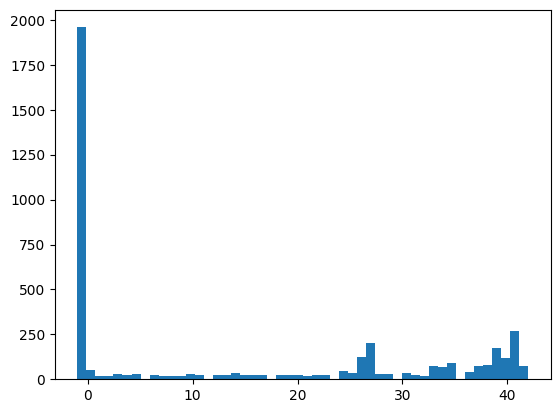

In [30]:
### plot household n_adults from .h5

import matplotlib.pyplot as plt
import datetime
from matplotlib.lines import Line2D

SCENARIO = "scenario_" + str(n+1)
OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

with h5py.File(H5_FILE, "r") as f:
    # for region in regions:
    # agent = "/households/hh_type"
    agent = "/individuals/employment_industry"
    path_str = region + agent

    if path_str in f:
        temp = f[path_str][()].astype(int)
        print(np.shape(temp))
        print(temp[0])
        print(type(temp[0][0]))

        plt.hist(
            temp[0], 
            bins=50,
        )
plt.show()


income
consumption
wealth
debt


C:\Users\LSTERN\AppData\Local\Temp\ipykernel_984\4093778104.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  figure.tight_layout(pad=20.0) # pad increases space around subplots


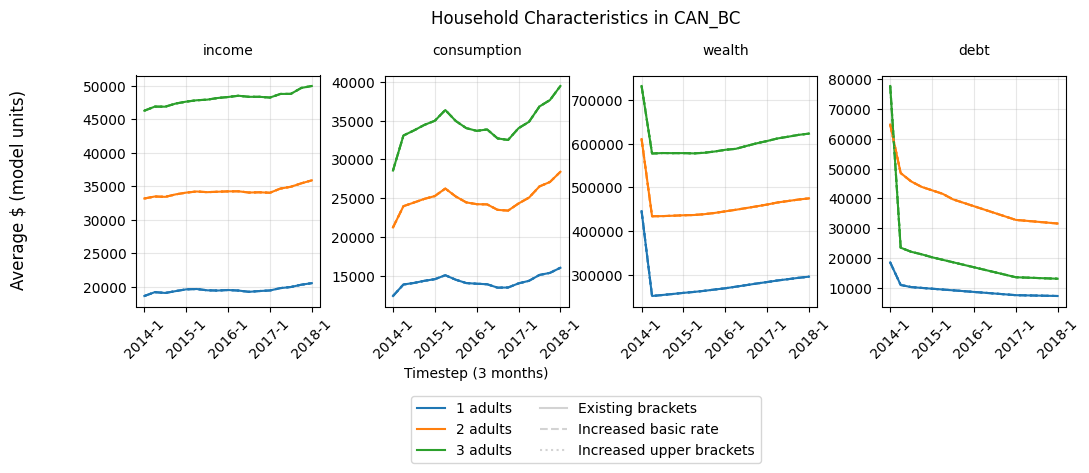

In [34]:
### plot household characteristics - filtered by household type - with subplots

import matplotlib.pyplot as plt
import datetime
from matplotlib.lines import Line2D

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
region = "CAN_BC"
variable_str = []
variable_str.append("income")
variable_str.append("consumption")
variable_str.append("wealth")
variable_str.append("debt")
num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

### subpplot setup
num_rows = 1
num_columns = num_variables

figure, axis = plt.subplots(num_rows, num_columns, sharex=True, sharey=False)
rot = 45
subplot_size = 3
text_size = 8
xtick_freq = 4
max_title_length = 15
figure.set_figheight(num_rows*subplot_size)
figure.set_figwidth(num_columns*subplot_size)
figure.tight_layout(pad=20.0) # pad increases space around subplots
figure.subplots_adjust(wspace=0.35, hspace=0.25)

### describe graph
figure.suptitle(f"Household Characteristics in {region}", y=1.1)  
figure.supylabel("Average $ (model units)")
# ax = plt.gca() 
# ax.tick_params("x", rotation=rot)

### scenario variables
linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        agent = "/households/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)

                n_adults = 3
                for j in range(n_adults):
                    data_filtered = np.zeros_like(data)
                    average_data_filtered = np.zeros(len(ts_time))

                    # filter by household type
                    for t in range(len(ts_households_n_adults['CAN_BC'])):
                        n_individual_filter = 0
                        
                        for k in range(len(ts_households_n_adults['CAN_BC'][0])):
                            if ts_households_n_adults['CAN_BC'][t][k] == j+1:
                                data_filtered[t][k] = data[t][k]
                                n_individual_filter += 1
                                average_data_filtered[t] += data[t][k]
                        # print(f"{properties[j]} t: {t} n: {n_individual_filter} data_tot {data_filtered[t].sum()}")
                        average_data_filtered[t] /= (n_individual_filter * base_config.scale)   
                        # print(f"\average_data_filtered {average_data_filtered[t]} ")

                    # total consumption
                    total_data_filtered = data_filtered.sum(axis=1)

                    axis[i].plot(
                        ts_time, 
                        average_data_filtered,
                        color=COLOURS[j], 
                        label=str(ts_tax_policy[n][region])[0] + " " + variable_str[i] + " {j} adult",
                        linestyle=linestyles[n],
                    )
                    axis[i].set_title(variable_str[i], fontsize=10, pad=15)
                    axis[i].grid(True, alpha=0.3)
                    axis[i].tick_params("x", rotation=45)
                    axis[i].set_xticks(ts_time[::xtick_freq])

### custom legend
PROVINCE_LABELS_LIST = list(PROVINCE_LABELS.values())
# linestyles = ['solid', 'dashed', 'dotted', 'dashdot']
# markers = ['o','^','s','D','x','*']       # use if not enough linestyles

legend_labels = []
for k in range(n_adults):
    legend_labels.append(str(k+1) + " adults")
# for j in range(len(tax_policy)):
#     legend_labels.append("rate = " + str(tax_policy[j].get_rate()))
legend_labels.append("Existing brackets")
legend_labels.append("Increased basic rate")
legend_labels.append("Increased upper brackets")
legend_labels.append("Flat default")

legend_lines = []
for k in range(n_adults):
    legend_lines.append(Line2D([0], [0], color = COLOURS[k], linestyle="-"))
for j in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

figure.legend(
    legend_lines, 
    legend_labels,
    loc='center',                   # anchor point inside axes 
    bbox_to_anchor=(0.5, -0.3),         # relative coords (0,0) bottom-left, (1,1) top-right
    ncol=int(len(legend_labels)/3),
)

### graph attributes
# ax.set_yscale('log')
# ax.legend(fontsize=7, ncol=4)
# ax.set_xlim(left=1)             # exclude initialization timestep
# plt.tight_layout()
axis[1].set_xlabel("Timestep (3 months)")
FILENAME = str(datetime.date.today()) + "_D_characteristics_households_filtered_by_type_subplots_" + region + ".png"
figure.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


In [35]:
from macromodel.agents.individuals.individual_properties import (
    ActivityStatus,
    Education,
    Gender,
)
t = 0
k = 4
for t in range(TIMESTEPS):
    print(f"{k} {t} {ts_individuals_activity_status['CAN_BC'][t][k] == ActivityStatus.EMPLOYED}")        
    # NOTE: sign that individual ActivityStatus is not changing - constant demographics?

4 0 False
4 1 False
4 2 False
4 3 False
4 4 False
4 5 False
4 6 False
4 7 False
4 8 False
4 9 False
4 10 False
4 11 False
4 12 False
4 13 False
4 14 False
4 15 False


employee_income
income_from_unemployment_benefits
taxable_income
personal_income_tax_adjustment
personal_income_tax_paid


C:\Users\LSTERN\AppData\Local\Temp\ipykernel_984\156286228.py:65: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  figure.tight_layout(pad=20.0) # pad increases space around subplots


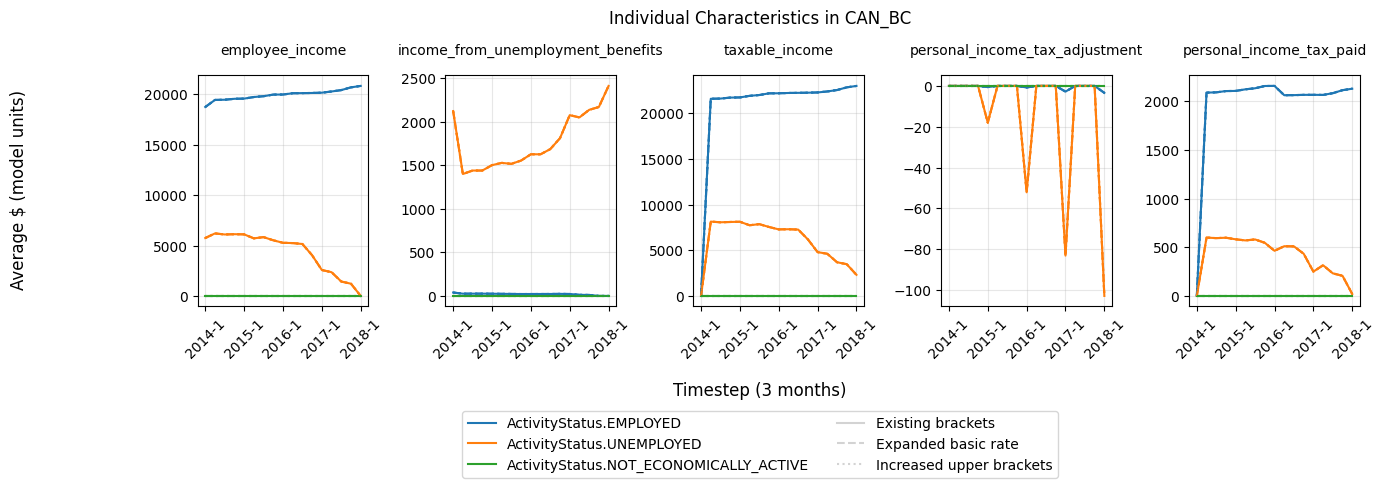

In [36]:
### plot individual characteristics - filtered by activity status - with subplots

import matplotlib.pyplot as plt
import datetime
from macromodel.agents.individuals.individual_properties import (
    ActivityStatus,
    Education,
    Gender,
)

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
region = "CAN_BC"
variable_str = []
variable_str.append("employee_income")
variable_str.append("income_from_unemployment_benefits")
variable_str.append("taxable_income")
variable_str.append("personal_income_tax_adjustment")
variable_str.append("personal_income_tax_paid")
num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

# properties to plot
properties = [
    ActivityStatus.EMPLOYED,
    ActivityStatus.UNEMPLOYED,
    ActivityStatus.NOT_ECONOMICALLY_ACTIVE,
]
num_properties = len(properties)

### subpplot setup
num_rows = 1
num_columns = num_variables

figure, axis = plt.subplots(num_rows, num_columns, sharex=True, sharey=False)
rot = 45
subplot_size = 3
text_size = 8
xtick_freq = 4
max_title_length = 15
figure.set_figheight(num_rows*subplot_size)
figure.set_figwidth(num_columns*subplot_size)
figure.tight_layout(pad=20.0) # pad increases space around subplots
figure.subplots_adjust(wspace=0.45, hspace=0.25)

### describe graph
figure.suptitle(f"Individual Characteristics in {region}", y=1.1)  
figure.supylabel("Average $ (model units)", x=0.0)
figure.supxlabel("Timestep (3 months)", y=-0.2)

### scenario variables
linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        agent = "/individuals/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)

                for j in range(num_properties):
                    data_filtered = np.zeros_like(data)
                    average_data_filtered = np.zeros(len(ts_time))

                    # filter by individual properties
                    for t in range(len(ts_individuals_activity_status[region])):
                        n_individual_filter = 0

                        for k in range(len(ts_individuals_activity_status[region][0])):
                            if ts_individuals_activity_status[region][t][k] == properties[j]:
                                data_filtered[t][k] = data[t][k]
                                n_individual_filter += 1
                                average_data_filtered[t] += data[t][k]
                        # print(f"{properties[j]} t: {t} n: {n_individual_filter} data_tot {data_filtered[t].sum()}")
                        average_data_filtered[t] /= (n_individual_filter * base_config.scale)   
                        # print(f"\average_data_filtered {average_data_filtered[t]} ")
                        
                    data_filtered.sum(axis=1)

                    axis[i].plot(
                        ts_time, 
                        average_data_filtered,
                        color=COLOURS[j], 
                        # label=str(f"{tax_policy[n].get_rate()} {variable_str[i]} {j} adult"),
                        linestyle=linestyles[n],
                    )
                    axis[i].set_title(variable_str[i], fontsize=10, pad=15)
                    axis[i].grid(True, alpha=0.3)
                    axis[i].tick_params("x", rotation=45)
                    axis[i].set_xticks(ts_time[::xtick_freq])

### custom legend
PROVINCE_LABELS_LIST = list(PROVINCE_LABELS.values())
# linestyles = ['solid', 'dashed', 'dotted', 'dashdot']
# markers = ['o','^','s','D','x','*']       # use if not enough linestyles

legend_labels = []
for k in range(num_properties):
    legend_labels.append(str(properties[k]))
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for k in range(num_properties):
    legend_lines.append(Line2D([0], [0], color = COLOURS[k], linestyle="-"))
for j in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

figure.legend(
    legend_lines, 
    legend_labels,
    loc='center',                   # anchor point inside axes 
    bbox_to_anchor=(0.5, -0.35),         # relative coords (0,0) bottom-left, (1,1) top-right
    ncol=int(len(legend_labels)/3),
)

### graph attributes
# FILENAME = str(datetime.date.today()) + "_D_characteristics_individuals_filtered_by_activity_status_subplots" + region + ".png"
FILENAME = str(datetime.date.today()) + "_TEST_" + region + ".png"
figure.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


employee_income
income_from_unemployment_benefits
taxable_income
personal_income_tax_paid


C:\Users\LSTERN\AppData\Local\Temp\ipykernel_984\2028496767.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  figure.tight_layout(pad=20.0) # pad increases space around subplots
C:\Users\LSTERN\AppData\Local\Temp\ipykernel_984\2028496767.py:116: RuntimeWarning: invalid value encountered in scalar divide
  average_data_filtered[t] /= (n_individual_filter * base_config.scale)


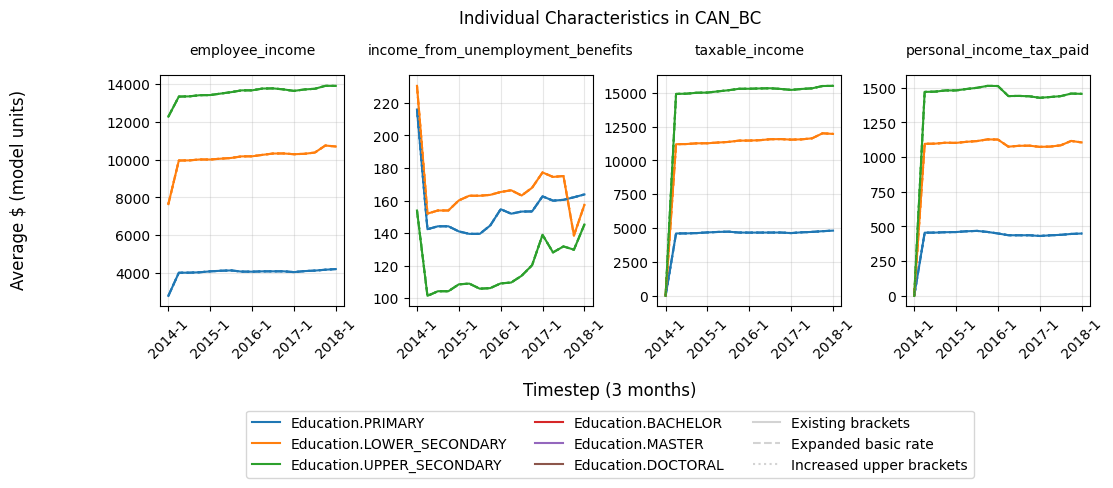

In [37]:
### plot individual characteristics - filtered by education - with subplots

import matplotlib.pyplot as plt
import datetime
from macromodel.agents.individuals.individual_properties import (
    ActivityStatus,
    Education,
    Gender,
)

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
region = "CAN_BC"
variable_str = []
variable_str.append("employee_income")
variable_str.append("income_from_unemployment_benefits")
variable_str.append("taxable_income")
variable_str.append("personal_income_tax_paid")
num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

# properties to plot
properties = [
    Education.PRIMARY,
    Education.LOWER_SECONDARY,
    Education.UPPER_SECONDARY,
    Education.BACHELOR,
    Education.MASTER,
    Education.DOCTORAL,
]

# NONE = 0  # No formal education
# PRIMARY = 1  # Primary education
# LOWER_SECONDARY = 2  # Lower secondary education
# UPPER_SECONDARY = 3  # Upper secondary education
# POST_SECONDARY = 4  # Post-secondary non-tertiary
# SHORT_TERTIARY = 5  # Short-cycle tertiary
# BACHELOR = 6  # Bachelor's or equivalent
# MASTER = 7  # Master's or equivalent
# DOCTORAL = 8  # Doctoral or equivalent

num_properties = len(properties)

### subpplot setup
num_rows = 1
num_columns = num_variables

figure, axis = plt.subplots(num_rows, num_columns, sharex=True, sharey=False)
rot = 45
subplot_size = 3
text_size = 8
xtick_freq = 4
max_title_length = 15
figure.tight_layout(pad=20.0) # pad increases space around subplots
plt.subplots_adjust(wspace=0.35, hspace=0.25)
figure.set_figheight(num_rows*subplot_size)
figure.set_figwidth(num_columns*subplot_size)

### describe graph
figure.suptitle(f"Individual Characteristics in {region}", y=1.1)  
figure.supylabel("Average $ (model units)", x=0.0)
figure.supxlabel("Timestep (3 months)", y=-0.2)

### scenario variables
linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        agent = "/individuals/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)

                for j in range(num_properties):
                    data_filtered = np.zeros_like(data)
                    average_data_filtered = np.zeros(len(ts_time))

                    # filter by individual properties
                    for t in range(len(ts_individuals_activity_status[region])):
                        n_individual_filter = 0

                        for k in range(len(ts_individuals_activity_status[region][0])):
                            if ts_individuals_education[region][t][k] == properties[j]:
                                data_filtered[t][k] = data[t][k]
                                n_individual_filter += 1
                                average_data_filtered[t] += data[t][k]
                        average_data_filtered[t] /= (n_individual_filter * base_config.scale) 

                    # total consumption
                    total_data_filtered = data_filtered.sum(axis=1)

                    axis[i].plot(
                        ts_time, 
                        average_data_filtered,
                        color=COLOURS[j], 
                        # label=str(tax_policy[n].get_rate()) + " " + variable_str[i] + " {j} adult",
                        linestyle=linestyles[n],
                    )
                    axis[i].set_title(variable_str[i], fontsize=10, pad=15)
                    axis[i].grid(True, alpha=0.3)
                    axis[i].tick_params("x", rotation=45)
                    axis[i].set_xticks(ts_time[::xtick_freq])

### custom legend
PROVINCE_LABELS_LIST = list(PROVINCE_LABELS.values())
# linestyles = ['solid', 'dashed', 'dotted', 'dashdot']
# markers = ['o','^','s','D','x','*']       # use if not enough linestyles

legend_labels = []
for k in range(num_properties):
    legend_labels.append(str(properties[k]))
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for k in range(num_properties):
    legend_lines.append(Line2D([0], [0], color = COLOURS[k], linestyle="-"))
for j in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[j % len(linestyles)]))

figure.legend(
    legend_lines, 
    legend_labels,
    loc='center',                   # anchor point inside axes 
    bbox_to_anchor=(0.5, -0.35),         # relative coords (0,0) bottom-left, (1,1) top-right
    ncol=int(len(legend_labels)/3),
)

### graph attributes
FILENAME = str(datetime.date.today()) + "_D_characteristics_individuals_filtered_by_education_subplots" + region + "_ALL" + ".png"
figure.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


cpi
ppi


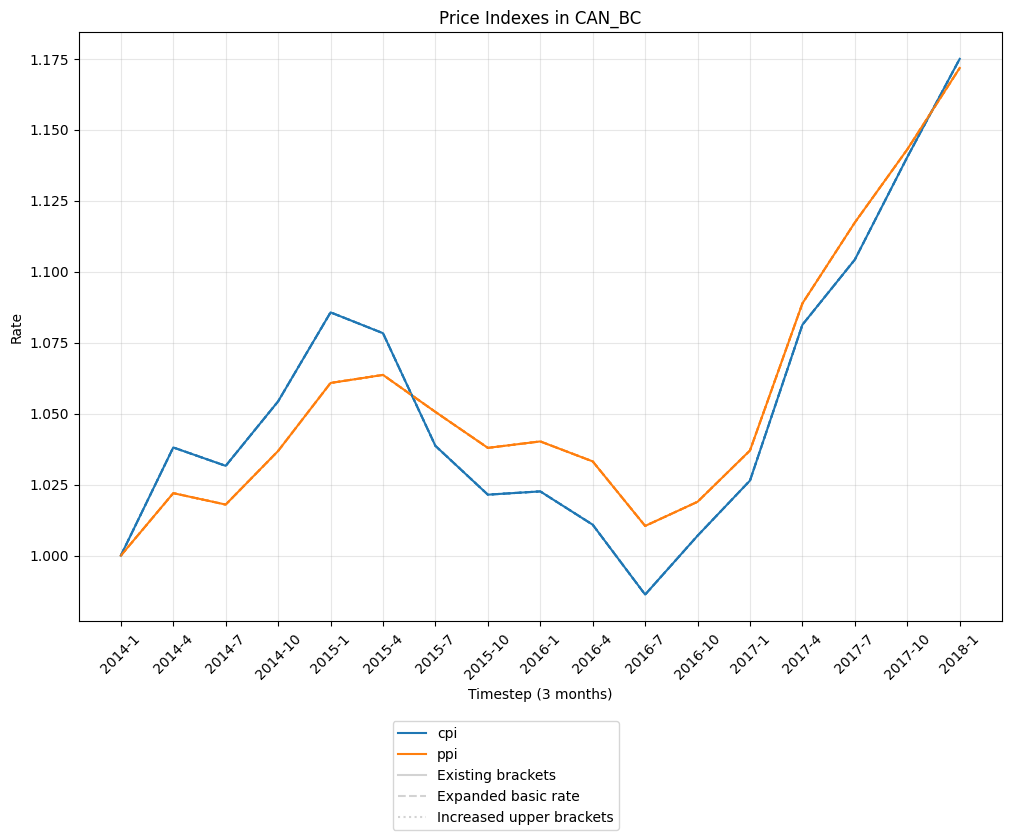

In [38]:
### plot economy price indexes

import matplotlib.pyplot as plt
import datetime

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
variable_str = []
# variable_str.append("unemployment_rate")
variable_str.append("cpi")
variable_str.append("ppi")
# variable_str.append("household_insolvency_rate")

num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        region = "CAN_BC"
        agent = "/economy/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)
                # total consumption
                total_data= data.sum(axis=1)
                # total consumption of 

            ax.plot(
                ts_time, 
                total_data,
                color=COLOURS[i], 
                label=variable_str[i],
                linestyle=linestyles[n],
                )

# custom legend
legend_labels = []
for i in range(num_variables):
    legend_labels.append(variable_str[i])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for i in range(num_variables):
    legend_lines.append(Line2D([0], [0], color = COLOURS[i], linestyle="-"))
for n in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[n]))

fig.legend(
    legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.1), loc="center", ncol=int(len(legend_labels)/4)
    # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
    # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title(f"Price Indexes in {region}") 
ax.set_ylabel("Rate")

# ax.set_yscale('log')
# ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_F_economy_price_index" + region + "_ALL" + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


unemployment_rate


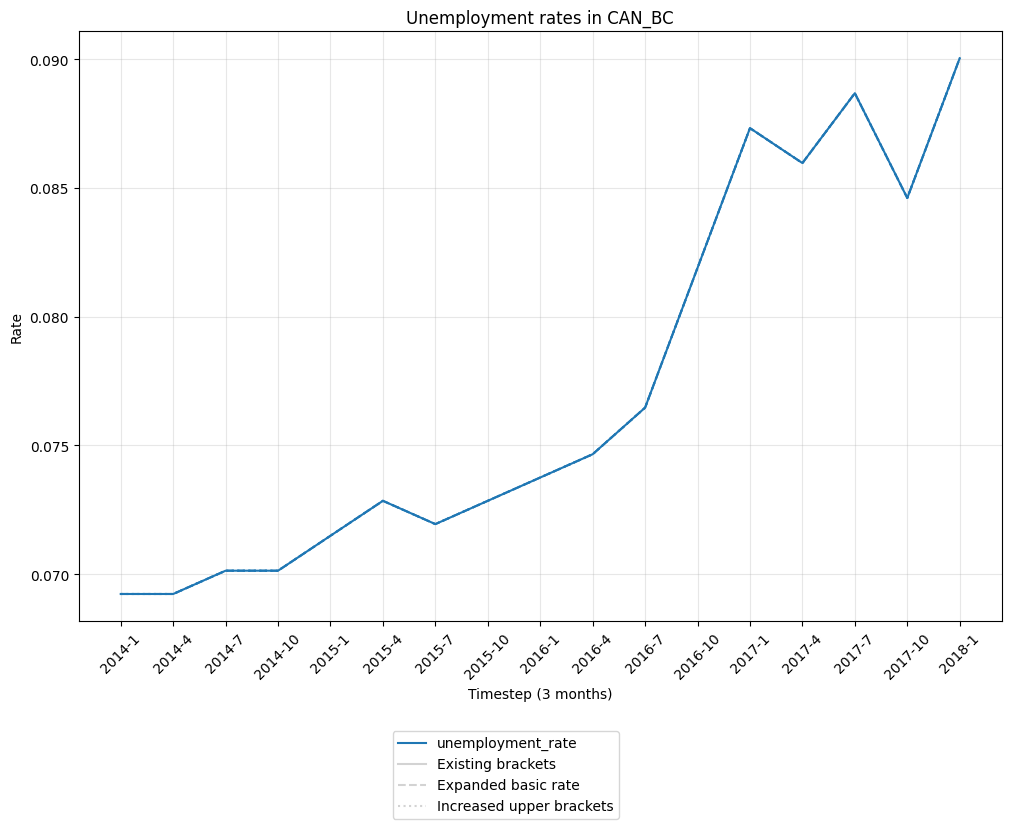

In [39]:
### plot economy unemployment rate

import matplotlib.pyplot as plt
import datetime

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

COLOURS = [
    '#1f77b4', 
    '#ff7f0e', 
    '#2ca02c', 
    '#d62728', 
    '#9467bd', 
    '#8c564b', 
    '#e377c2', 
    '#7f7f7f', 
    '#bcbd22', 
    '#17becf'
]

# variables to plot
variable_str = []
variable_str.append("unemployment_rate")
# variable_str.append("job_reallocation_rate")
# variable_str.append("vacancy_rate")
# variable_str.append("household_insolvency_rate")

num_variables = len(variable_str)
for i in range(num_variables):
    print(variable_str[i])
path_str = []

linestyles = ['solid', 'dashed', 'dotted', 'dashdot']

# fig, ax = plt.subplots(figsize=(10, 5))
fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)
    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        region = "CAN_BC"
        agent = "/economy/"
        for i in range(num_variables):
            path_str = region + agent + variable_str[i]

            if path_str in f:
                data = f[path_str][()].astype(float)
                # total consumption
                total_data= data.sum(axis=1)
                # total consumption of 

            ax.plot(
                ts_time, 
                total_data,
                color=COLOURS[i], 
                label=variable_str[i],
                linestyle=linestyles[n],
                )

# custom legend
legend_labels = []
for i in range(num_variables):
    legend_labels.append(variable_str[i])
for j in range(len(scenario_labels)):
    legend_labels.append(scenario_labels[j])

legend_lines = []
for i in range(num_variables):
    legend_lines.append(Line2D([0], [0], color = COLOURS[i], linestyle="-"))
for n in range(n_scenarios):
    legend_lines.append(Line2D([0], [0], color = "lightgrey", linestyle=linestyles[n]))

fig.legend(
    legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.1), loc="center", ncol=int(len(legend_labels)/4)
    # legend_lines, legend_labels, bbox_to_anchor = (0.5,-0.03), loc="lower center", ncol=len(legend_labels)
    # legend_lines, legend_labels, bbox_to_anchor = (1.5,1.025), loc="upper right"
)

ax.set_title(f"Unemployment rates in {region}") 
ax.set_ylabel("Rate")

# ax.set_yscale('log')
# ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlabel("Timestep (3 months)")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# plt.tight_layout()
FILENAME = str(datetime.date.today()) + "_E_economy_unemployment" + region + "_ALL" + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()


taxable_income
taxable_income_employment
taxable_income_unemployment
taxable_income_rental


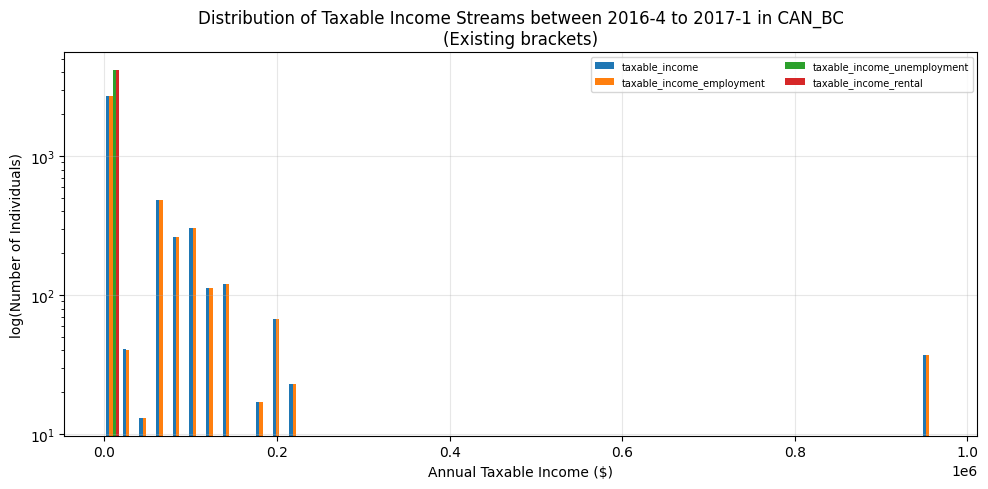

mean: $44,098.02
median: $1,125.37
min: $0.00
max: $965,363.71


In [40]:
### plot ALL taxable income histograms

import matplotlib.pyplot as plt
import datetime

SCENARIO = "scenario_1"
OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

# year to plot
year = 2

# variables to plot
variable_str = []
variable_str.append("taxable_income")
variable_str.append("taxable_income_employment")
variable_str.append("taxable_income_unemployment")
variable_str.append("taxable_income_rental")

num_variables = len(variable_str)

for i in range(num_variables):
    print(variable_str[i])

path_str = []
annual_data = []

fig, ax = plt.subplots(figsize=(10, 5))
with h5py.File(H5_FILE, "r") as f:
    # for region in regions:
    region = "CAN_BC"
    agent = "/individuals/"
    for i in range(num_variables):
        path_str = region + agent + variable_str[i]

        if path_str in f:
            data = f[path_str][()].astype(float)
            annual_data.append((
                data[1 + (0 + year*4)] 
                + data[1 + (1 + year*4)] 
                + data[1 + (2 + year*4)] 
                + data[1 + (3 + year*4)]
                )/base_config.scale)

    ax.hist([annual_data[0], annual_data[1], annual_data[2], annual_data[3]], 
            bins=50,
            # color=['blue', 'red', 'green', 'orange'], 
            label=[variable_str[0], variable_str[1], variable_str[2], variable_str[3]]
            )
    
ax.set_title(
    f"Distribution of Taxable Income Streams between {ts_time[1 + (0 + year*4)]} to {ts_time[1 + (3 + year*4)]} in {region}"
    + f"\n({scenario_labels[0]})"
    ) 
ax.set_xlabel("Annual Taxable Income ($)")
ax.set_ylabel("log(Number of Individuals)")

ax.set_yscale('log')
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
fig.tight_layout()
FILENAME = str(datetime.date.today()) + "_G_taxable_income_histogram_" + SCENARIO + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()

# Metrics
print(f"mean: ${np.mean(annual_data[0]):,.2f}")
print(f"median: ${np.median(annual_data[0]):,.2f}")      # why is median 0?
print(f"min: ${np.min(annual_data[0]):,.2f}")
print(f"max: ${np.max(annual_data[0]):,.2f}")


employee_income


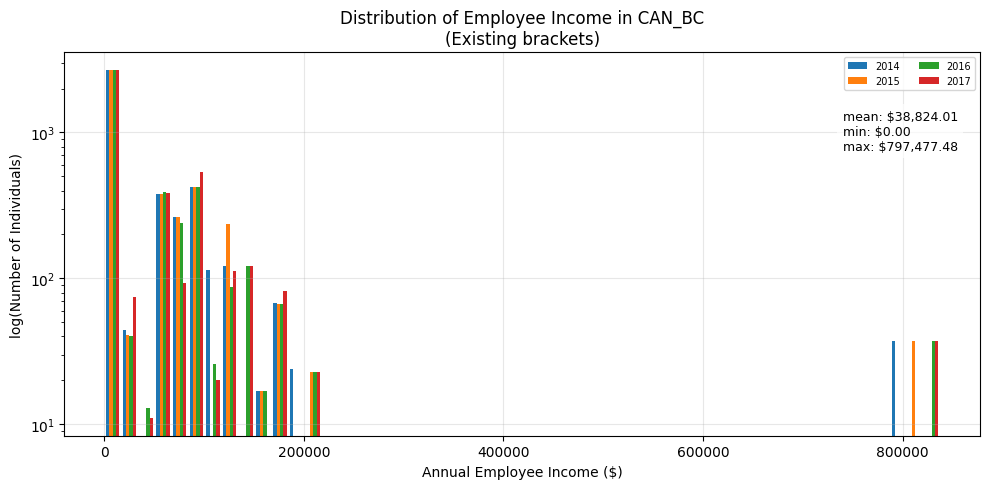

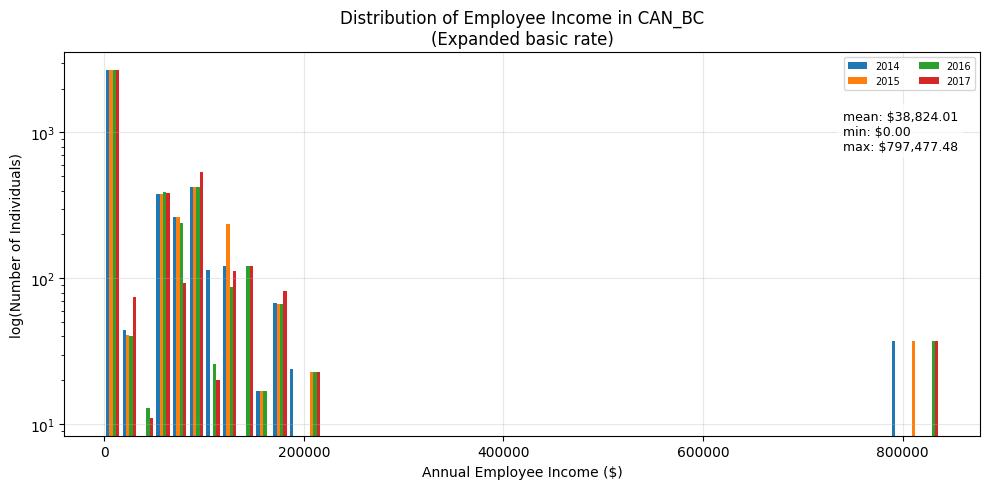

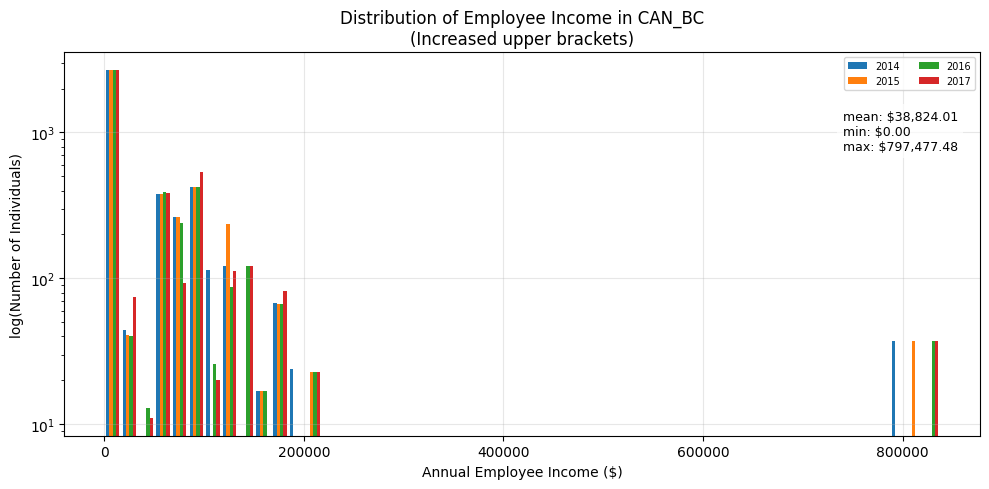

In [43]:
### plot ALL employmee income histograms over time - SIMPLIFIED compare scenarios

import matplotlib.pyplot as plt
import datetime

### common
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

# year to plot
years = []
n_years = int((len(ts_time) - 1)/4)

# variables to plot
variable_str = []
variable_str.append("employee_income")

num_variables = len(variable_str)

for i in range(num_variables):
    print(variable_str[i])

path_str = []

### iterate over scenarios
for n in range(n_scenarios):
    SCENARIO = "scenario_" + str(n+1)

    OUTPUT_FILENAME  = "results_" + SCENARIO + ".h5"
    H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME

    annual_data = []

    fig, ax = plt.subplots(figsize=(10, 5))
    with h5py.File(H5_FILE, "r") as f:
        # for region in regions:
        region = "CAN_BC"
        agent = "/individuals/"
        for yr in range(n_years):
            year = ts_time[1 + (0 + yr*4)]
            years.append(year[:-2])

            for i in range(num_variables):
                path_str = region + agent + variable_str[i]

                if path_str in f:
                    data = f[path_str][()].astype(float)
                    annual_data.append((
                        data[1 + (0 + yr*4)] 
                        + data[1 + (1 + yr*4)] 
                        + data[1 + (2 + yr*4)] 
                        + data[1 + (3 + yr*4)]
                        )/base_config.scale)
        
        ax.hist(annual_data, 
                bins=50, 
                label=years
                )
        
    ax.set_title(
        f"Distribution of Employee Income in {region}"
        + f"\n({scenario_labels[n]})"
    ) 
    ax.set_xlabel("Annual Employee Income ($)")
    ax.set_ylabel("log(Number of Individuals)")
    ax.set_yscale('log')
    ax.legend(fontsize=7, ncol=2)

    info = (
        f"mean: ${np.mean(annual_data[0]):,.2f}" +
        f"\nmin: ${np.min(annual_data[0]):,.2f}" + 
        f"\nmax: ${np.max(annual_data[0]):,.2f}"                
    )
    ax.text(
        0.85, 0.85,             # Position in Axes coordinates
        info,                   # Text string
        transform=ax.transAxes, # Use Axes coordinate system
        ha='left',              # Horizontal alignment
        va='top',               # Vertical alignment
        fontsize=9,             # Font size
        color='k',              # Text color
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # Optional background
    )

    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    FILENAME = str(datetime.date.today()) + "_F_taxable_income_histogram_trajectory_" + SCENARIO + ".png"
    fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
    plt.show()



taxable_income
taxable_income_employment
taxable_income_unemployment
taxable_income_rental


NameError: name 'tax_policy' is not defined

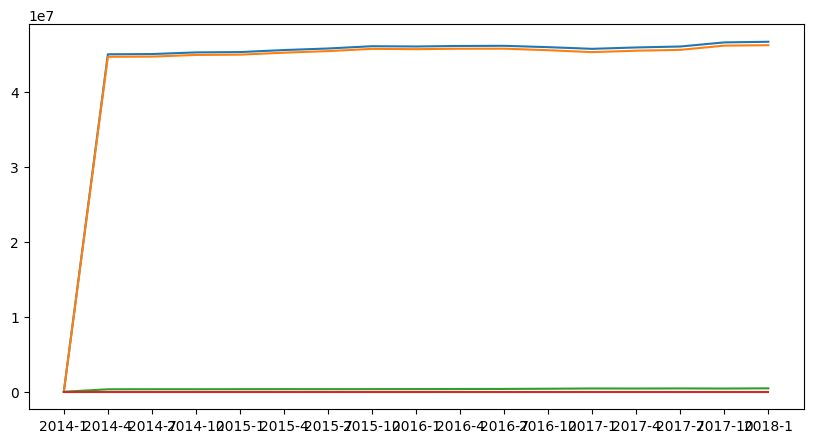

In [44]:
### plot ALL total taxable income streams over time

import matplotlib.pyplot as plt
import datetime

H5_FILE = OUTPUT_DIRECTORY / OUTPUT_FILENAME
PROVINCE_LABELS = {
    "CAN_AB": "Alberta",      "CAN_BC": "British Columbia", "CAN_MB": "Manitoba",
    "CAN_NB": "New Brunswick","CAN_NL": "Newfoundland",     "CAN_NS": "Nova Scotia",
    "CAN_ON": "Ontario",      "CAN_PE": "PEI",              "CAN_QC": "Quebec",
    "CAN_SK": "Saskatchewan",
}

# variables to plot
variable_str = []
variable_str.append("taxable_income")
variable_str.append("taxable_income_employment")
variable_str.append("taxable_income_unemployment")
variable_str.append("taxable_income_rental")

num_variables = len(variable_str)

for i in range(num_variables):
    print(variable_str[i])

path_str = []
data = []

fig, ax = plt.subplots(figsize=(10, 5))
with h5py.File(H5_FILE, "r") as f:
    # for region in regions:
    region = "CAN_BC"
    agent = "/individuals/"
    for i in range(num_variables):
        path_str = region + agent + variable_str[i]

        if path_str in f:
            data.append(f[path_str][()].astype(float)/1000)

        ax.plot(ts_time, np.sum(data[i], axis=1), 
            linestyle='-', 
            label=variable_str[i]
            )
    
ax.set_title(
    f"Total Taxable Income Components in {region}"
    + f"\nrate: {tax_policy[0].get_rate()}"
) 
ax.set_xlabel("Time")
# ax.set_xlim(left=1)             # exclude initialization timestep
ax.tick_params("x", rotation=45)
# ax.set_xticks(ts_time[::4])   # control xtick frequency
ax.set_ylabel("Total Taxable Income ($)")

# ax.set_yscale('log')          # log plot toggle
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
fig.tight_layout()
FILENAME = str(datetime.date.today()) + "_taxable_income_trajectory_" + SCENARIO + ".png"
fig.savefig(OUTPUT_DIRECTORY / FILENAME, bbox_inches='tight')
plt.show()
